# Семинар: рекуррентные сети

Одни и те же RNN, LSTM и GRU в двух задачах: угадываем язык фамилии по буквам и генерируем текст по символам.

In [1]:
# Установка зависимостей в окружение текущего ноутбука.
%pip install torch numpy pandas matplotlib


In [2]:
from pathlib import Path
import math, random, time, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(min(4, torch.get_num_threads()))
DATA = Path('data'); DATA.mkdir(exist_ok=True)

def download(url, name):
    path = DATA / name
    if not path.exists():
        with urllib.request.urlopen(url, timeout=60) as response:
            path.write_bytes(response.read())
    return path

print('Устройство:', device, '| PyTorch:', torch.__version__)


Устройство: cpu | PyTorch: 2.11.0+cpu


# Блок 1. Фамилия → язык

По фамилии, записанной латиницей, угадываем язык происхождения: `Ivanov` → Russian, `Nakamura` → Japanese, `Rossi` → Italian. 18 языков, около 20 тысяч фамилий — датасет из туториала PyTorch.

Это задача «много входов → один выход»: RNN читает фамилию по буквам, а предсказание делаем по состоянию после последней буквы.

`E` — размер эмбеддинга буквы, `H` — размер скрытого состояния, `B` — размер батча, `C` — число языков.

In [3]:
H, B, E = 64, 32, 32
NAME_STEPS = 2000
PAD = 0  # номер символа-заполнителя

## Данные

Каждая строка файла `data/names/<Язык>.txt` — одна фамилия. Точные повторы пар «фамилия, язык» убираем.

строк в файлах: 20074, без повторов: 18015, языков: 18


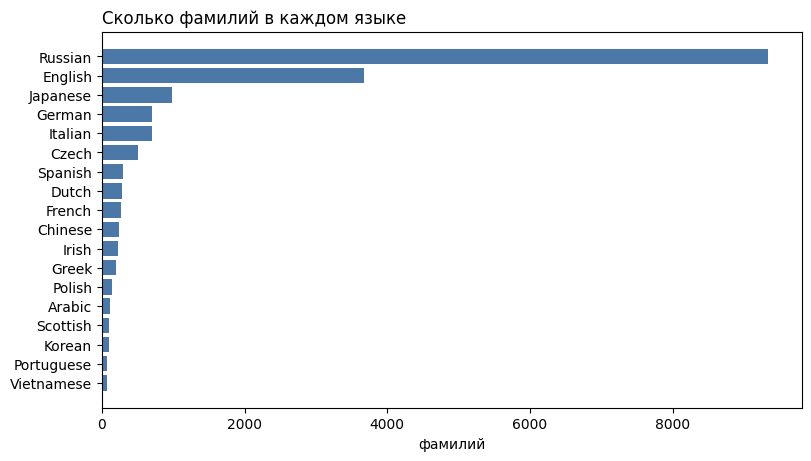

In [4]:
zip_path = download('https://download.pytorch.org/tutorial/data.zip', 'names.zip')
with zipfile.ZipFile(zip_path) as z:
    files = sorted(f for f in z.namelist() if f.startswith('data/names/') and f.endswith('.txt'))
    raw = [(line.strip(), Path(f).stem) for f in files
           for line in z.read(f).decode('utf-8').splitlines() if line.strip()]
names_df = pd.DataFrame(sorted(set(raw)), columns=['name', 'lang'])
LANGS = sorted(names_df['lang'].unique())
C = len(LANGS)
lang_id = {lang: i for i, lang in enumerate(LANGS)}
print(f'строк в файлах: {len(raw)}, без повторов: {len(names_df)}, языков: {C}')

counts = names_df['lang'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
ax.barh(counts.index, counts.values, color='#4C78A8')
ax.set_xlabel('фамилий'); ax.set_title('Сколько фамилий в каждом языке', loc='left')
plt.show()

## Разбиение

Делим 80/10/10 по **уникальным фамилиям**: одна фамилия целиком попадает в одну часть. Иначе одна и та же строка (например, `Adam`, который есть и в English, и в French) оказалась бы и в train, и в test — и тест проверял бы запоминание, а не умение угадывать язык новой фамилии.

In [5]:
rng = np.random.default_rng(0)
unique_names = rng.permutation(sorted(names_df['name'].unique()))
n = len(unique_names)
split_of = {name: 'train' if i < .8 * n else 'val' if i < .9 * n else 'test'
            for i, name in enumerate(unique_names)}
names_df['split'] = names_df['name'].map(split_of)
print(names_df['split'].value_counts().to_dict())
print('фамилий с несколькими языками:', int((names_df.groupby('name')['lang'].nunique() > 1).sum()))

{'train': 14435, 'val': 1794, 'test': 1786}
фамилий с несколькими языками: 469


## Токенизация: одна буква — один токен

Сеть работает с числами, поэтому фамилию превращаем в последовательность номеров:

1. **Токен — один символ.** Буква, апостроф, пробел — каждый отдельный токен. Никаких слогов и подслов: `Ivanov` → `I v a n o v`.
2. **Словарь** — все символы, которые встретились в train, плюс два служебных: `<PAD>` = 0 (заполнитель) и `<UNK>` = 1 (символ, которого не было в train).
3. **Кодирование:** каждый символ заменяем его номером в словаре. Дальше `Embedding` превратит каждый номер в вектор из `E` чисел.

In [6]:
train_names = names_df[names_df['split'] == 'train']
name_itos = ['<PAD>', '<UNK>'] + sorted({ch for name in train_names['name'] for ch in name})
name_stoi = {ch: i for i, ch in enumerate(name_itos)}

def encode_name(name):
    return torch.tensor([name_stoi.get(ch, 1) for ch in name], dtype=torch.long)

print('размер словаря:', len(name_itos))
print('словарь:', ' '.join(name_itos[2:]))
ids = encode_name('Ivanov')
print('Ivanov →', ids.tolist(), '→', [name_itos[i] for i in ids])

размер словаря: 85
словарь:   ' , - / 1 : A B C D E F G H I J K L M N O P Q R S T U V W X Y Z a b c d e f g h i j k l m n o p q r s t u v w x y z   ß à á ã ä è é ê ì í ñ ò ó õ ö ù ú ü ą ł ń Ś ż
Ivanov → [17, 56, 35, 48, 49, 56] → ['I', 'v', 'a', 'n', 'o', 'v']


## Батчи и паддинг

Фамилии разной длины, а батч — прямоугольный тензор. Поэтому короткие фамилии **дополняем справа** токеном `<PAD>` до длины самой длинной в батче (`pad_sequence`). Ниже первые фамилии батча, `·` — паддинг.

In [7]:
def pad_batch(batch):
    xs, ys = zip(*batch)
    return nn.utils.rnn.pad_sequence(xs, batch_first=True, padding_value=PAD), torch.tensor(ys)

def name_loader(split, shuffle=False):
    part = names_df[names_df['split'] == split]
    data = [(encode_name(name), lang_id[lang]) for name, lang in zip(part['name'], part['lang'])]
    return DataLoader(data, batch_size=B if shuffle else 512, shuffle=shuffle, collate_fn=pad_batch)

names_train, names_val, names_test = name_loader('train', True), name_loader('val'), name_loader('test')
xb, yb = next(iter(names_train))
print('Батч:', tuple(xb.shape), xb.dtype, '→', tuple(yb.shape), yb.dtype)
for row, lang in zip(xb[:6], yb[:6]):
    print(f"{''.join('·' if i == PAD else name_itos[i] for i in row.tolist()):<20} {LANGS[lang]}")

Батч: (32, 13) torch.int64 → (32,) torch.int64
Dobrajansky··        Russian
Jilyardy·····        Russian
Puga·········        Spanish
Timashov·····        Russian
Agutin·······        Russian
Ruadhain·····        Irish


## Метрики и бейзлайн: мешок букв

Метрики: **accuracy** — доля угаданных фамилий, и **balanced accuracy** — сначала доля угаданных внутри каждого языка, потом среднее по языкам. Russian — почти половина данных, поэтому смотрим в первую очередь на balanced accuracy.

Бейзлайн — **мешок букв**: считаем, сколько раз каждая буква встречается в фамилии, и подаём эти счётчики в один `Linear` — это логистическая регрессия. Порядок букв она не видит: `Ivanov` и `vonavI` для неё одинаковые.

In [8]:
def scores(pred, true):
    pred, true = np.asarray(pred), np.asarray(true)
    recalls = [(pred[true == c] == c).mean() for c in np.unique(true)]
    return {'accuracy': float((pred == true).mean()), 'balanced accuracy': float(np.mean(recalls))}

def char_counts(split):
    part = names_df[names_df['split'] == split]
    counts = torch.zeros(len(part), len(name_itos))   # (фамилий, словарь): сколько раз каждая буква
    for row, name in enumerate(part['name']):
        for i in encode_name(name):
            counts[row, i] += 1
    return counts, torch.tensor(part['lang'].map(lang_id).to_numpy())

bag_x, bag_y = char_counts('train')
seed_everything(0)
bag = nn.Linear(len(name_itos), C)                    # логистическая регрессия
opt = torch.optim.Adam(bag.parameters(), lr=0.05)
for step in range(300):
    loss = F.cross_entropy(bag(bag_x), bag_y)
    opt.zero_grad(); loss.backward(); opt.step()

@torch.no_grad()
def bag_predict(split):
    counts, y = char_counts(split)
    return bag(counts).argmax(-1).numpy(), y.numpy()

print('Мешок букв, val:', {k: round(v, 3) for k, v in scores(*bag_predict('val')).items()})

Мешок букв, val: {'accuracy': 0.719, 'balanced accuracy': 0.285}


## Задание 1.1. RNN-ячейка

**Как устроена RNN.** Сеть читает фамилию по одной букве. У неё есть память `h` — вектор из `H` чисел. Сначала `h` нулевой. На каждой букве ячейка смешивает эмбеддинг буквы с памятью и выдаёт обновлённую память. После последней буквы память идёт в `Linear`, который выдаёт по логиту на каждый язык.

![](attachment:rnn_names.png)

**Один шаг ячейки** — формула:

$$h_{\text{новое}} = \tanh(W_x\, x + b_x + W_h\, h + b_h)$$

`b_x` и `b_h` — сдвиги (bias), у каждого слоя свой.

**Что написать:** `MyRNNCell.forward(x, h)`.

| | форма | что это |
|---|---|---|
| `x` | `(B, d)` | вход одного шага: у нас эмбеддинг буквы, `d = E` |
| `h` | `(B, H)` | память до этого шага |
| вернуть | `(B, H)` | память после этого шага |

В `__init__` уже есть два слоя: `self.W_x = nn.Linear(d, H)` и `self.W_h = nn.Linear(H, H)`. Каждый `nn.Linear` считает «матрица · вектор + сдвиг», так что по формуле:

1. `self.W_x(x)` — вклад буквы, `(B, H)`;
2. `self.W_h(h)` — вклад памяти, `(B, H)`;
3. сложить и применить `torch.tanh`.

In [9]:
class MyRNNCell(nn.Module):
    def __init__(self, d, H):
        super().__init__()
        self.H = H
        self.W_x = nn.Linear(d, H)
        self.W_h = nn.Linear(H, H)

    def init_state(self, x):
        return x.new_zeros(x.shape[0], self.H)

    def forward(self, x, h):
        # TODO: реализуйте переход состояния
        raise NotImplementedError

## Задание 1.2. Проход по последовательности

Допишите `run_cell(cell, x, state=None)`: `x` — `(B, L, d)`, `L` — длина последовательности. Пройти по оси времени, на каждом шаге обновить состояние ячейкой и сохранить `h_t`. Вернуть все состояния `(B, L, H)` (склеить через `torch.stack(..., dim=1)`) и последнее состояние. `state=None` — старт с нулей, `cell.init_state(x)`.

In [10]:
def run_cell(cell, x, state=None):
    if state is None:
        state = cell.init_state(x)
    # TODO: пройдите по времени, соберите h_t и верните (outputs, state).
    raise NotImplementedError


## Задание 1.3. Модель целиком

Ячейку и проход по буквам мы написали. Теперь собираем модель, которая по фамилии выдаёт ответ. Она состоит из трёх частей, применяемых по очереди:

1. `inp` — `Embedding`: номер каждой буквы → вектор из `E` чисел;
2. `rnn` — рекуррентный слой (`nn.RNN`): читает эти векторы по порядку, как наш `run_cell`, и выдаёт память после каждой буквы;
3. `head` — `Linear`: память → ответ, по логиту на каждый язык.

`SeqModel(inp, rnn, head, last_only)` хранит эти три части. Допишите `forward(x, state=None)`, где `x` — номера букв формы `(B, L)`:

* применить `inp`, затем `rnn`. `rnn` вернёт `out` формы `(B, L, H)` — память после каждой буквы — и последнее состояние;
* если `last_only=True` — это наш случай, один ответ на фамилию: в голову подаём память после **последней настоящей буквы** каждой фамилии. Длины: `lengths = (x != PAD).sum(1)`. Циклом по фамилиям берём `out[b, lengths[b] - 1]` и собираем в тензор `(B, H)` через `torch.stack`;
* если `last_only=False` — в голову подаём `out` целиком, ответ на каждой позиции. Сейчас это не нужно, но позже та же модель пригодится для задачи, где ответ нужен после каждого символа;
* вернуть `(ответ головы, состояние)`.

`out[:, -1]` здесь **неверно**: у коротких фамилий последний шаг — паддинг.

Слои PyTorch создаём с `batch_first=True`: по умолчанию они ждут вход `(L, B, d)`.

In [11]:
class SeqModel(nn.Module):
    def __init__(self, inp, rnn, head, last_only=False):
        super().__init__()
        self.inp, self.rnn, self.head = inp, rnn, head
        self.last_only = last_only

    def forward(self, x, state=None):
        # TODO: inp → rnn → head; при last_only — состояние на последней настоящей букве
        raise NotImplementedError

## Обучение

Цикл обучения дан (ячейка свёрнута): Adam, ограничение нормы градиента единицей, лучшие веса — по val loss. Каждый батч стартует с нулевого состояния: фамилии друг от друга не зависят.

In [12]:
@torch.no_grad()
def evaluate(model, loader, loss_fn):
    was_training = model.training
    model.eval()
    total, count = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        pred, _ = model(xb)
        total += loss_fn(pred, yb).item() * yb.numel()
        count += yb.numel()
    model.train(was_training)
    if count == 0:
        raise ValueError('Пустой набор для оценки')
    return total / count

def fit(model, train_loader, val_loader, loss_fn, steps, check_every=100):
    model.to(device).train()
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    best, best_weights, history = float('inf'), None, []
    recent = []
    iterator = iter(train_loader)
    for step in range(1, steps + 1):
        try:
            xb, yb = next(iterator)
        except StopIteration:
            iterator = iter(train_loader)
            xb, yb = next(iterator)
        xb, yb = xb.to(device), yb.to(device)
        pred, _ = model(xb)
        loss = loss_fn(pred, yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        recent.append(loss.item())
        if step % check_every == 0 or step == steps:
            val = evaluate(model, val_loader, loss_fn)
            train = sum(recent) / len(recent)
            recent = []
            history.append((step, train, val))
            print(f'{step:4d}: train loss={train:.4f}, val loss={val:.4f}')
            if val < best:
                best = val
                best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_weights)
    return history


## Задание 1.4. Модель и лосс

* `make_classifier(rnn_layer)`: собрать `SeqModel` из трёх частей — `Embedding` на `len(name_itos)` букв в `E` чисел с `padding_idx=PAD`; рекуррентный слой `rnn_layer(E, H, batch_first=True)`; голова `Linear` в `C` логитов; `last_only=True`. Сюда передаём сам класс слоя: `nn.RNN`, позже `nn.LSTM` и `nn.GRU` — остальная модель не меняется.
* `classifier_loss(logits, target)`: логиты `(B, C)`, цели — номера языков `(B,)`, средняя `F.cross_entropy`. **Без softmax** — он уже внутри `cross_entropy`.

In [13]:
def make_classifier(rnn_layer):
    # TODO: SeqModel с эмбеддингом букв, слоем rnn_layer и головой на C языков
    raise NotImplementedError

def classifier_loss(logits, target):
    # TODO: средняя кросс-энтропия
    raise NotImplementedError

In [14]:
models, records = {}, {}

@torch.no_grad()
def predict_classes(model, loader):
    model.eval()
    preds, trues = [], []
    for xb, yb in loader:
        preds.append(model(xb.to(device))[0].argmax(-1).cpu())
        trues.append(yb)
    return torch.cat(preds).numpy(), torch.cat(trues).numpy()

def train_classifier(kind, rnn_layer):
    seed_everything(0)
    model = make_classifier(rnn_layer)
    start_time = time.perf_counter()
    fit(model, names_train, names_val, classifier_loss, NAME_STEPS, check_every=500)
    seconds = time.perf_counter() - start_time
    models.setdefault(kind, {})['names'] = model
    records.setdefault(kind, {}).update({f'{k} val': v for k, v in scores(*predict_classes(model, names_val)).items()})
    records[kind]['Параметры'] = sum(p.numel() for p in model.parameters())
    records[kind]['Время, с'] = round(seconds, 1)
    print(pd.DataFrame(records).T.round(3))
    return model

## RNN на фамилиях

In [15]:
rnn_names = train_classifier('rnn', nn.RNN)

NotImplementedError: 

## Задание 1.5. LSTM

Отдельная память `c` рядом с `h`. Состояние — пара `(h, c)`, обе части `(B, H)`:

$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\qquad h_t=o_t\odot\tanh(c_t).$$

* `f` (forget) — сколько старой памяти оставить, `i` (input) — сколько записать из кандидата `g`, `o` (output) — сколько памяти выдать в `h`;
* гейты — `sigmoid` (от 0 до 1), кандидат `g` — `tanh`; `⊙` — поэлементное умножение.

Гейты и кандидат считаются так же, как память в RNN — у каждого свои два слоя, для буквы и для памяти:

$$i=\sigma(W_{xi}x+W_{hi}h),\quad f=\sigma(W_{xf}x+W_{hf}h),\quad g=\tanh(W_{xg}x+W_{hg}h),\quad o=\sigma(W_{xo}x+W_{ho}h).$$

Допишите `MyLSTMCell.forward(x, state)`: вернуть новую пару `(h, c)`. Все восемь слоёв уже созданы в `__init__`: `self.W_xi`, `self.W_hi`, `self.W_xf`, … Сдвиги — внутри каждого `Linear`.

In [ ]:
class MyLSTMCell(nn.Module):
    def __init__(self, d, H):
        super().__init__()
        self.H = H
        self.W_xi, self.W_hi = nn.Linear(d, H), nn.Linear(H, H)
        self.W_xf, self.W_hf = nn.Linear(d, H), nn.Linear(H, H)
        self.W_xg, self.W_hg = nn.Linear(d, H), nn.Linear(H, H)
        self.W_xo, self.W_ho = nn.Linear(d, H), nn.Linear(H, H)

    def init_state(self, x):
        z = x.new_zeros(x.shape[0], self.H)
        return z, z.clone()

    def forward(self, x, state):
        # TODO: реализуйте переход состояния
        raise NotImplementedError

## Задание 1.6. Проход по времени для пары

Перепишите `run_cell` в ячейке ниже: если состояние — кортеж `(h, c)`, в выходы кладём только `h`, а на следующий шаг передаём всю пару. Для RNN и GRU (один тензор) функция должна работать как раньше.

In [ ]:
def run_cell(cell, x, state=None):
    if state is None:
        state = cell.init_state(x)
    outputs = []
    for t in range(x.shape[1]):
        state = cell(x[:, t], state)
        # TODO: state может быть парой (h, c) — в outputs кладём только h.
        # Для RNN и GRU (один тензор) всё должно работать как раньше.
        raise NotImplementedError
    return torch.stack(outputs, dim=1), state


## LSTM на фамилиях

Меняется только рекуррентный слой; данные, голова, лосс и число шагов те же.

In [ ]:
lstm_names = train_classifier('lstm', nn.LSTM)

## GRU

Отдельной памяти нет, гейтов два: reset `r` — сколько прошлого пустить в кандидата `n`, update `z` — в какой пропорции смешать старое состояние и кандидата.

$$r=\sigma(W_{xr}x+W_{hr}h),\qquad z=\sigma(W_{xz}x+W_{hz}h),$$
$$n=\tanh(W_{xn}x+r\odot W_{hn}h),\qquad h_t=(1-z)\odot n+z\odot h_{t-1}.$$

У каждого слагаемого свой `Linear` (сдвиги внутри). Реализация дана — найдите в коде каждую формулу. В PyTorch `z` — доля **старого** состояния, а `r` умножает уже готовое `W_hn h + b_hn` — вместе со сдвигом.

In [ ]:
class MyGRUCell(nn.Module):
    def __init__(self, d, H):
        super().__init__()
        self.H = H
        self.W_xr, self.W_hr = nn.Linear(d, H), nn.Linear(H, H)
        self.W_xz, self.W_hz = nn.Linear(d, H), nn.Linear(H, H)
        self.W_xn, self.W_hn = nn.Linear(d, H), nn.Linear(H, H)

    def init_state(self, x):
        return x.new_zeros(x.shape[0], self.H)

    def forward(self, x, h):
        r = torch.sigmoid(self.W_xr(x) + self.W_hr(h))
        z = torch.sigmoid(self.W_xz(x) + self.W_hz(h))
        n = torch.tanh(self.W_xn(x) + r * self.W_hn(h))
        return (1 - z) * n + z * h

## GRU на фамилиях

In [ ]:
gru_names = train_classifier('gru', nn.GRU)

## Тест

Один раз — на отложенных фамилиях.

In [ ]:
rows_names = {'Мешок букв': scores(*bag_predict('test'))}
for kind in ['rnn', 'lstm', 'gru']:
    rows_names[kind.upper()] = scores(*predict_classes(models[kind]['names'], names_test))
print(pd.DataFrame(rows_names).T.round(3))

### Где модель путается

Матрица ошибок на валидации: строка — настоящий язык, столбец — предсказанный, в клетке — доля фамилий строки.

In [ ]:
pred, true = predict_classes(gru_names, names_val)
cm = np.zeros((C, C))
for t, p in zip(true, pred):
    cm[t, p] += 1
cm = cm / cm.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(8, 7), layout='constrained')
im = ax.imshow(cm, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(C), LANGS, rotation=90); ax.set_yticks(range(C), LANGS)
ax.set_xlabel('предсказано'); ax.set_ylabel('на самом деле')
fig.colorbar(im, ax=ax, shrink=.8)
plt.show()

# Блок 2. Текст по символам

Текст Достоевского: на каждой позиции предсказываем следующий символ, потом генерируем продолжения. Ячейки, `SeqModel` и цикл обучения — из блока 1. Вход тот же — номера символов через `Embedding`; меняется то, что голова теперь работает на **каждой** позиции.

* `T=80` — длина фрагмента, `V` — размер словаря, `E` — размер эмбеддинга символа.
* Части train/val/test — 80/10/10 по тексту. Словарь — **только по train**, незнакомые символы → `<UNK>`.
* Все фрагменты одной длины, поэтому паддинг здесь не нужен.

In [ ]:
T, E = 80, 32
LM_STEPS = 3000  # на CPU ~10–20 с на модель
TEXT_LIMIT = 600_000


In [ ]:
text_path = download('https://raw.githubusercontent.com/DLSchool/deep-learning-school/master/17.%20RNN/dostoevsky.txt', 'dostoevsky.txt')
text = text_path.read_text(encoding='utf-8').replace('﻿', '').replace(' ', ' ')[:TEXT_LIMIT]
a, b = int(.8*len(text)), int(.9*len(text))
train_text, val_text, test_text = text[:a], text[a:b], text[b:]
itos = ['<UNK>'] + sorted(set(train_text))
stoi = {ch: i for i, ch in enumerate(itos)}
V = len(itos)
def encode(s):
    return torch.tensor([stoi.get(ch, 0) for ch in s], dtype=torch.long)
def decode(ids):
    return ''.join(itos[int(i)] if int(i) != 0 else '�' for i in ids)
train_ids, val_ids, test_ids = map(encode, [train_text, val_text, test_text])
print('V =', V, '| Длины частей:', len(train_ids), len(val_ids), len(test_ids))
print('Доля неизвестных символов на валидации:', float((val_ids == 0).float().mean()))
print(train_text[:250])


## Задание 2.1. Входы и цели

Допишите `CharChunks.__getitem__(index)`: начало `start` дано, вернуть `(x, y)` — два среза длины `T`, `y` сдвинут на один символ вперёд. «привет» → `x` = «приве», `y` = «ривет».

In [ ]:
class CharChunks(Dataset):
    def __init__(self, ids, T):
        self.ids, self.T = ids, T
    def __len__(self):
        return max(0, (len(self.ids)-1)//self.T)
    def __getitem__(self, index):
        if not 0 <= index < len(self):
            raise IndexError(index)
        start = index * self.T
        # TODO: вход и цель со сдвигом на один символ
        raise NotImplementedError


In [ ]:
train_chars, val_chars, test_chars = [CharChunks(ids, T) for ids in (train_ids, val_ids, test_ids)]
x, y = train_chars[0]
print('Вход:', decode(x[:60])); print('Цель:', decode(y[:60]))
lm_train = DataLoader(train_chars, batch_size=B, shuffle=True)
lm_val = DataLoader(val_chars, batch_size=128)
lm_test = DataLoader(test_chars, batch_size=128)


In [ ]:
xb, yb = next(iter(lm_train))
print('Батч текста:', tuple(xb.shape), xb.dtype, '→', tuple(yb.shape), yb.dtype)
print('Вход:', decode(xb[0, :40]))
print('Цель:', decode(yb[0, :40]))


## Бейзлайны

Без контекста: равномерно (`1/V`) и по частотам train со сглаживанием +1. Метрика — перплексия `exp(CE)`; у равномерной она ровно `V`.

In [ ]:
counts = torch.bincount(train_ids, minlength=V).float() + 1
unigram_probs = counts/counts.sum()

def char_targets(dataset):
    return torch.cat([dataset[i][1] for i in range(len(dataset))])

def frequency_ce(dataset):
    return -unigram_probs[char_targets(dataset)].log().mean().item()

print('Перплексия текста, валидация:')
print({'Равномерная': V, 'Частотная': math.exp(frequency_ce(val_chars))})


## Задание 2.2. Модель и лосс LM

| | Блок 1 | Блок 2 |
|---|---|---|
| Вход | номера букв фамилии, с паддингом | номера символов, фрагменты по `T` |
| `inp` | `Embedding` | `Embedding(V, E)` |
| В голову | последняя настоящая буква | каждая позиция |
| Выход | `C` логитов | `V` логитов на каждой позиции |
| Лосс | CE по батчу | CE по всем `B·T` позициям |

* `make_lm(rnn_layer)`: эмбеддинг символов `Embedding(V, E)`, рекуррентный слой `rnn_layer(E, H, batch_first=True)`, голова `Linear` в `V` логитов на **каждой** позиции (`last_only=False`).
* `lm_loss(logits, target)`: логиты `(B, T, V)`, цели `(B, T)`, средняя `F.cross_entropy` по всем позициям. Склейте батч и время: `(B·T, V)` и `(B·T,)`. **Без softmax.**

In [ ]:
def make_lm(rnn_layer):
    # TODO: тот же SeqModel с эмбеддингом, слоем rnn_layer и головой на V символов
    raise NotImplementedError

def lm_loss(logits, target):
    # TODO: средняя кросс-энтропия по всем символам
    raise NotImplementedError

In [ ]:
def train_language(kind, rnn_layer):
    seed_everything(0)
    model = make_lm(rnn_layer)
    start_time = time.perf_counter()
    fit(model, lm_train, lm_val, lm_loss, LM_STEPS, check_every=500)
    seconds = time.perf_counter()-start_time
    ce = evaluate(model, lm_val, lm_loss)
    models.setdefault(kind, {})['lm'] = model
    records.setdefault(kind, {}).update({
        'Лосс val': ce, 'Перплексия val': math.exp(ce),
        'Параметры LM': sum(p.numel() for p in model.parameters()),
        'Время LM, с': round(seconds, 1),
    })
    print(kind, 'Перплексия val:', math.exp(ce))
    return model

lm = train_language('rnn', nn.RNN)


## Задание 2.3. Генерация

Допишите `generate(model, prompt, n, temperature)`: вернуть затравку плюс ровно `n` новых символов.

1. Прогнать всю затравку через модель один раз.
2. Взять логиты **последней** позиции, поделить на `temperature`, применить softmax.
3. Выбрать символ через `torch.multinomial`.
4. Подать в модель **только этот символ** формы `(1, 1)` и сохранённое состояние.
5. Повторить `n` раз.

При обучении состояние сбрасываем, при генерации — **несём**: текст непрерывный. `temperature < 1` — ближе к самому вероятному символу, `> 1` — больше случайности.

In [ ]:
@torch.no_grad()
def generate(model, prompt, n=200, temperature=1.0):
    if not prompt or temperature <= 0 or n < 0:
        raise ValueError('Нужны непустая затравка, temperature > 0 и n >= 0')
    was_training = model.training
    model.eval()
    try:
        # TODO: затравка, состояние, цикл выбора следующих символов
        raise NotImplementedError
    finally:
        model.train(was_training)


In [ ]:
prompt = 'Князь '
if any(ch not in stoi for ch in prompt):
    prompt = train_text[:12]
for temperature in [0.5, 1.0, 1.3]:
    seed_everything(7)
    print(f'\nТемпература {temperature}:')
    print(generate(lm, prompt, n=250, temperature=temperature))


## LSTM и GRU на тексте

Меняется только слой. `generate` передаёт состояние целиком, так что пара `(h, c)` работает без изменений. Перед каждой генерацией — одинаковый seed.

In [ ]:
lstm_lm = train_language('lstm', nn.LSTM)
print(pd.DataFrame(records).T.loc[['rnn', 'lstm'], ['Лосс val', 'Перплексия val', 'Параметры LM']].round(3))


In [ ]:
gru_lm = train_language('gru', nn.GRU)
print(pd.DataFrame(records).T[['Лосс val', 'Перплексия val', 'Параметры LM']].round(3))
for kind in ['rnn', 'lstm', 'gru']:
    seed_everything(7)
    print('\n', kind.upper(), 'при temperature=1:')
    print(generate(models[kind]['lm'], prompt, n=200, temperature=1.0))


## Тест

In [ ]:
rows_lm = [
    {'Модель': 'Равномерная', 'Средний лосс': math.log(V), 'Перплексия': V},
    {'Модель': 'Частотная', 'Средний лосс': frequency_ce(test_chars), 'Перплексия': math.exp(frequency_ce(test_chars))},
]
for kind in ['rnn', 'lstm', 'gru']:
    ce = evaluate(models[kind]['lm'], lm_test, lm_loss)
    rows_lm.append({'Модель': kind.upper(), 'Средний лосс': ce, 'Перплексия': math.exp(ce)})
print(pd.DataFrame(rows_lm).set_index('Модель').round(3))


## Приколы

### Где модель уверена

Вероятность, которую модель дала **настоящему** следующему символу на куске валидации; светлее — увереннее. На вход подаётся настоящий текст, а не сгенерированный.

In [ ]:
@torch.no_grad()
def show_next_char_confidence(model, fragment):
    ids = encode(fragment).to(device)
    logits, _ = model(ids[:-1][None])
    probs = logits.softmax(-1)[0]
    prob = np.array([probs[t, ids[t + 1]].item() for t in range(len(ids) - 1)])
    fig, ax = plt.subplots(figsize=(12, 2))
    im = ax.imshow(prob[None], vmin=0, vmax=1, cmap='viridis', aspect='auto')
    ax.set_xticks(range(len(prob)), [repr(c)[1:-1] for c in fragment[1:]], fontsize=10)
    ax.set_yticks([]); ax.set_xlabel('Настоящий следующий символ')
    fig.colorbar(im, ax=ax, label='Вероятность'); plt.tight_layout(); plt.show()

show_next_char_confidence(lm, val_text[200:241])

### Гейты LSTM

Обученная LSTM, прогнанная нашей ячейкой с её весами. Строка — одна из первых 8 координат, столбец — прочитанный символ; светлее — гейт ближе к 1.

In [ ]:
@torch.no_grad()
def load_lstm(cell, layer):
    # nn.LSTM хранит веса гейтов одной матрицей, друг под другом в порядке i, f, g, o.
    H = cell.H
    gates = [(cell.W_xi, cell.W_hi), (cell.W_xf, cell.W_hf), (cell.W_xg, cell.W_hg), (cell.W_xo, cell.W_ho)]
    for k, (W_x, W_h) in enumerate(gates):
        rows = slice(k * H, (k + 1) * H)
        W_x.weight.copy_(layer.weight_ih_l0[rows]); W_x.bias.copy_(layer.bias_ih_l0[rows])
        W_h.weight.copy_(layer.weight_hh_l0[rows]); W_h.bias.copy_(layer.bias_hh_l0[rows])

@torch.no_grad()
def show_gate_maps(values, fragment):
    fig, axes = plt.subplots(len(values), 1, figsize=(12, 2.2*len(values)), constrained_layout=True)
    for ax, (name, value) in zip(np.atleast_1d(axes), values.items()):
        im = ax.imshow(value[:, :8].T.cpu(), aspect='auto', vmin=0, vmax=1, cmap='viridis')
        ax.set_ylabel(name + '\nкоордината')
        ax.set_xticks(range(len(fragment)), [repr(c)[1:-1] for c in fragment], fontsize=9)
        ax.set_yticks(range(8), range(1, 9))
    fig.colorbar(im, ax=list(np.atleast_1d(axes)), label='Значение гейта')
    plt.show()

@torch.no_grad()
def inspect_lstm(model, fragment):
    cell = MyLSTMCell(E, H).to(device)
    load_lstm(cell, model.rnn)
    emb = model.inp(encode(fragment)[None].to(device))
    h, c = cell.init_state(emb)
    values = {'f: сохранение': [], 'i: запись': [], 'o: выход': []}
    for t in range(emb.shape[1]):
        x = emb[:, t]
        values['f: сохранение'].append(torch.sigmoid(cell.W_xf(x) + cell.W_hf(h))[0])
        values['i: запись'].append(torch.sigmoid(cell.W_xi(x) + cell.W_hi(h))[0])
        values['o: выход'].append(torch.sigmoid(cell.W_xo(x) + cell.W_ho(h))[0])
        h, c = cell(x, (h, c))
    show_gate_maps({k: torch.stack(v) for k, v in values.items()}, fragment)

inspect_lstm(lstm_lm, val_text[200:232])
seed_everything(7)
print(generate(lstm_lm, prompt, n=250))

### Гейты GRU

In [ ]:
@torch.no_grad()
def load_gru(cell, layer):
    # nn.GRU хранит веса одной матрицей, друг под другом в порядке r, z, n.
    H = cell.H
    parts = [(cell.W_xr, cell.W_hr), (cell.W_xz, cell.W_hz), (cell.W_xn, cell.W_hn)]
    for k, (W_x, W_h) in enumerate(parts):
        rows = slice(k * H, (k + 1) * H)
        W_x.weight.copy_(layer.weight_ih_l0[rows]); W_x.bias.copy_(layer.bias_ih_l0[rows])
        W_h.weight.copy_(layer.weight_hh_l0[rows]); W_h.bias.copy_(layer.bias_hh_l0[rows])

@torch.no_grad()
def inspect_gru(model, fragment):
    cell = MyGRUCell(E, H).to(device)
    load_gru(cell, model.rnn)
    emb = model.inp(encode(fragment)[None].to(device))
    h = cell.init_state(emb)
    values = {'r: вклад прошлого в кандидат': [], 'z: доля старого состояния': []}
    for t in range(emb.shape[1]):
        x = emb[:, t]
        values['r: вклад прошлого в кандидат'].append(torch.sigmoid(cell.W_xr(x) + cell.W_hr(h))[0])
        values['z: доля старого состояния'].append(torch.sigmoid(cell.W_xz(x) + cell.W_hz(h))[0])
        h = cell(x, h)
    show_gate_maps({k: torch.stack(v) for k, v in values.items()}, fragment)

inspect_gru(gru_lm, val_text[200:232])

## Материалы
* [Karpathy: The Unreasonable Effectiveness of RNNs](https://karpathy.github.io/2015/05/21/rnn-effectiveness/) — char-level LM и что он выучивает.
* Документация PyTorch: [RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html), [LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html), [GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html), [pad_sequence](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pad_sequence.html).